# Figure 2D — Where metapredict V3 excels: the five best-predicted CAID3 proteins

The CAID3 Disorder-PDB proteins on which metapredict V3 has the highest per-protein AUC, each shown as four tracks: (1) metapredict V3 score with its predicted IDRs shaded, (2) the top CAID3 methods PUNCH2, SPOT-Disorder2 and AlphaFold-rsa (colours as in panel B), (3) PDB structural evidence (resolved as a monomer, as a homo-oligomer or only in a hetero-complex, in dark to light grey; in a construct but with missing density, hatched orange; not in any structure, hatched grey), and (4) the Disorder-PDB reference labels (colours as in panel C). Each protein is headed by its DisProt ID and metapredict V3 per-protein AUC. The PDB codes behind each resolved block are printed below rather than written on the figure. Track names and the legend are drawn here and not on panel E, which sits to the right with the same tracks.

**How it is made.** Per-protein AUC of metapredict V3 (3.1.0) is computed over each target's scored residues. Only targets of 40–500 residues with at least 15 disordered and 15 ordered scored residues are considered, so every example has a real mix of order and disorder. Structural coverage comes from DisProt → SIFTS → PDBe (`data/pdb_cache` in the shared data directory, built by `data/pdb_cache_pipeline`).

**Output:** `figures/figure_2D.pdf`

In [1]:
from caid3_panels import load_predictions, load_reference
from figtools import apply_style, require_metapredict_3_1, save_panel
from ground_truth_panels import (OTHER_PREDICTORS, load_coverage, make_composite, print_pdb_codes,
                                 select_best_worst)

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

N_EXAMPLES = 5

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 43b92cd)


In [2]:
reference = load_reference()
predictions = load_predictions(['Metapredict-v3'] + [name for name, _ in OTHER_PREDICTORS])
metapredict_v3 = predictions.pop('Metapredict-v3')
coverage, coverage_pdbs = load_coverage()

selection = select_best_worst(reference, metapredict_v3, n=N_EXAMPLES)[0]
for tid, auc in selection:
    print(f'{tid}: per-protein AUC = {auc:.3f}')
print('PDB codes behind each resolved block (1-based residues):')
print_pdb_codes(selection, coverage, coverage_pdbs)

DP04263: per-protein AUC = 1.000
DP04172: per-protein AUC = 1.000
DP04290: per-protein AUC = 1.000
DP04309: per-protein AUC = 1.000
DP04297: per-protein AUC = 1.000
PDB codes behind each resolved block (1-based residues):
DP04263: 217-223 hetero-complex only: 9TFU; 286-341 hetero-complex only: 1CI6
DP04172: 20-96 monomer: 1UAW; 97-103 hetero-complex only: 2RS2; 109-200 monomer: 2MSS, 2MST, 5X3Y
DP04290: 147-220 hetero-complex only: 6XWS, 6XWT
DP04309: 95-168 monomer: 8S7A
DP04297: 99-121 hetero-complex only: 4B6H, 5KQ1, 5KQ4


Wrote figures/figure_2D.pdf


PosixPath('figures/figure_2D.pdf')

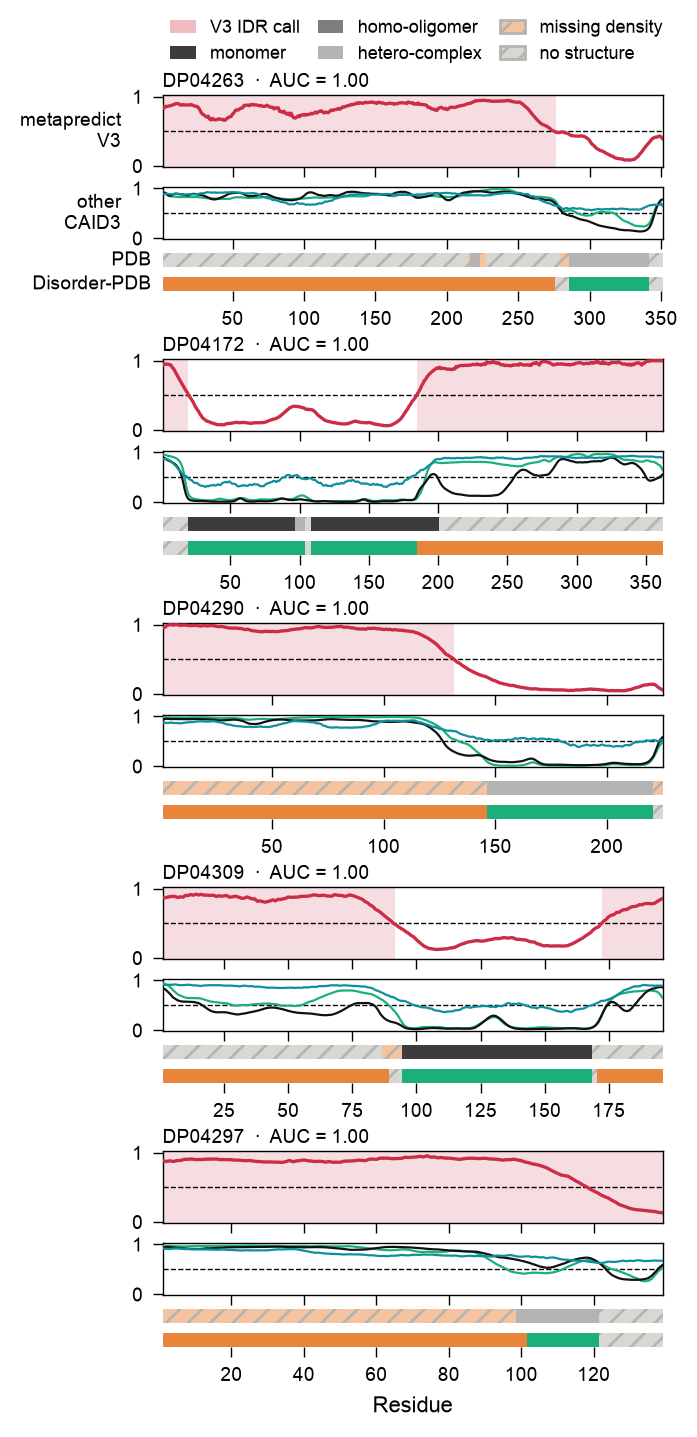

In [3]:
fig = make_composite(selection, reference, coverage, metapredict_v3, predictions, legend=True, track_labels=True)
save_panel(fig, 'figure_2D')